## <font color='black'> FlyFinder version 1.0 (4-panel images - Panasonic Camera )</font>
This notebook provides the sequence of instructions and commands for training a random forest classifer <br>
used during segmentation. It also give instructions and the commands of the whole process of segmentation.
<br><br>
If the model has been trained for a specific study setup, there will be no need to retrain, the user can <br>
immediately proceed to section 2 for first segmentation.

<u> Used camera model:</u><br>
Panosonic DC-ZS200<br>
<u>Settings</u>:<br> 
Aspect-ration 1:1<br>
Picture size: 3648 X 3648 pxl<br>
Filter settings: monochrome<br>
Use a 10-second selt timer for three pictures<br>


### Section 1: Training the classifier

- [1.1. Setting up initial parameters](#l1)
   
- [1.2. Training the random forest classifier](#l2)

### Section 2: Segmentation of images]
   
- [2.1. Performing the first segmentation](#l3)

- [2.2. Manual editing the failed images ](#l4)

- [2.3. Performing the second segmentation](#l5)

- [2.4. Creating the table of fly coordinates ](#l6)

- [2.5. Calculating the nearest neighbors distances](#l7)
 

### <font color='blue'><b>Section 1: Training the classifier</b></font>

### <font color='blue'> 1.0. Importing FlyFinder Functions </font>

In [1]:
from FF_utils import *

<a name="l1"></a>
### <font color='blue'> 1.1. Setting up initial parameters </font>

<b>  - The parameters for drawing:</b>

In [2]:
# Defining the colors
blue=(0,0,255); red=(255,0,0); magenta=(255,0,255); 

# Setting the line, point and figure size
pen=5;  # if pen=5 or less and the bottom lines is not visible, set it to 10
point=15; 
figSize=5

<b>  - Cropping the sides, masking the background and visualization (4-panel images): </b><br>
The <b>cropLeft</b>, <b>cropRight</b>, <b>cropTop</b> and <b>cropBottom</b> are used to crop the left, right,<br> 
top and  bottom sides the input images in case it is necessary.<br>
The <b>bottomMargin</b> and <b>topGap</b> parameters are used to demarcate the triangle such that the area inside the <br>
lines will be used while the area outside will be ignored. Different values can be tired to determine the best<br>
fit for a particular imaging setup. The demarcated pictures can be viewed in the next command

In [3]:
#Cropping the input image if necessary (pxl)
cropLeft4=0
cropRight4=0
cropTop4=0
cropBottom4=0

# Applying the mask:
# bottomMargin : correspond to the marging applied to the bottom of the image
# topgap : correspond to the distance between the two sides-triangle lines (at the top of the picture)   

bottomMargin4=100
topGap4=50

## Visualization
imagPath_="train_4p/"
#viewImageMargins4Panel(imagPath=imagPath_, bottomMargin=bottomMargin4, topGap=topGap4, cropLeft=cropLeft4, cropRight=cropRight4, cropTop=cropTop4, cropBottom=cropBottom4,  marginCol=blue, figSize=figSize, pen_=pen) 

<a name="l2"></a>
### <font color='blue'> 1.2. Training the random forest classifier </font>

After getting the best values of <b>bottomMargin</b> and <b>topGap</b> that best demarcate the <br>
triangle (i.e bottomMargin=60 topGap=10), they will be used to traini either a 1 or 4Panel-based random forest classifier.<br>

We can first see the script parameters like this:

In [4]:
! python FlyFinder_train.py --help


-* FlyFinder_v1.0 *-

usage: FlyFinder_train.py [-h] --modelName MODELNAME --plateType PLATETYPE
                          --nGaussianFilters NGAUSSIANFILTERS --nMedianFilters
                          NMEDIANFILTERS --nEstimators NESTIMATORS
                          --bottomMargin BOTTOMMARGIN --topGap TOPGAP
                          --cropLeft CROPLEFT --cropRight CROPRIGHT --cropTop
                          CROPTOP --cropBottom CROPBOTTOM --inPath INPATH

optional arguments:
  -h, --help            show this help message and exit
  --modelName MODELNAME
                        the name you want to give to your random forest
                        classifier.
  --plateType PLATETYPE
                        the 1 panel plate '1panel' or 4 panel plate '4panel'.
  --nGaussianFilters NGAUSSIANFILTERS
                        the number of gaussian filters. Default=40.
  --nMedianFilters NMEDIANFILTERS
                        the number of median filters. Default=40.
  --nEstimators N

<b>- Check if there are trained models:</b>

In [4]:
! python FlyFinder_train.py models


-* FlyFinder_v1.0 *-

Available trained random forest classifiers:

M4Panel_GF40_MF10_Es30_mar100_topG50_RFC




<b>- Viewing the directory of images used for segmentation: </b><br>
Note: the labelled image for training must have '_lbl' added to its name right before the '.jpg' file extension.

In [7]:
!ls /varidata/research/projects/mnp/tool.dev/FlyFinder_v1.0/train_4p/

4panels_400flies.jpg  4panels_400flies_lbl.jpg


<b>Executing the script that trains the random forest classifer (4-panel images):</b>

<u>Training settings:</u><br>
plateType = 4Panel (this can be changed to 1Panel if dealing with 1-panel/triangle images)<br>
Number of gaussian filters (nGaussianFilters=40) <br>
Median filters (nMedianFilters=10) <br>
Number of trees (nEstimators=30) <br>
bottomMargin = 100 <br> 
topGap = 50 <br>
cropLeft=0 <br>
cropRight=0 <br>
cropTop=0<br>
cropBottom=0<br>

In [6]:

! python FlyFinder_train.py --modelName "test_2nd" \
                            --plateType 4Panel \
                            --nGaussianFilters=40 \
                            --nMedianFilters=10 \
                            --nEstimators 30 \
                            --bottomMargin 100 \
                            --topGap 50 \
                            --cropLeft 0 \
                            --cropRight 0 \
                            --cropTop 0 \
                            --cropBottom 0 \
                            --inPath train_4p


-* FlyFinder_v1.0 *-


Training a random forest classifier for image segmentation ( 4Panel images) 
----------------------------------------------------------------------------------

Original images:['4panels_400flies.jpg']
Labeled images: ['4panels_400flies_lbl.jpg']
Training set size: 1 files

4panels_400flies.jpg	4panels_400flies_lbl.jpg

  -- Processing panel a --
  (1530708, 51)

  -- Processing panel b --
  (3060603, 51)

  -- Processing panel c --
  (4590378, 51)

  -- Processing panel d --
  (6119339, 51)
 
Dimensions after removing dupliate rows:
 (4892965, 51)
Trainning the RandomForestClassifier, number of estimators =  30 


 Confusion matrix:
[[475412   2350]
 [  2092   9443]]

Accuracy = 0.9909216692520085

Feature_importance:
--------------------
<class 'pandas.core.series.Series'>
 Gaussian_1       0.123379
Median_5          0.114954
Median_7          0.078686
Median_3          0.076066
Median_1          0.070537
 Gaussian_2       0.055768
Median_2          0.051057
M

<b>- The resulting model has:</b><br>
Accuracy = 0.991
Training duration =  13.6 min 

<b>- Viewing the fly Area density plot</b>

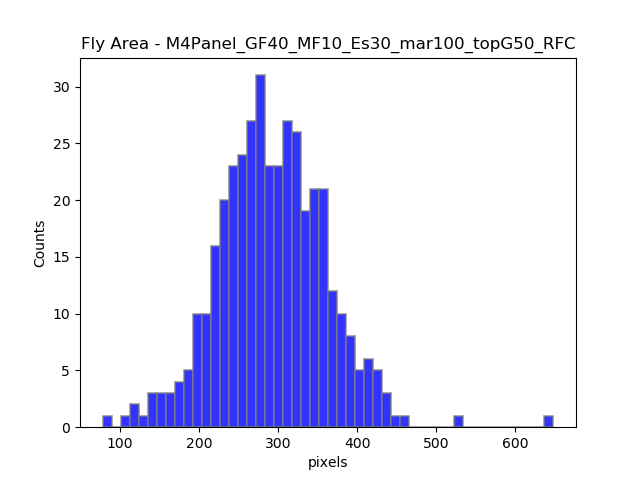

In [10]:

## Viewing the flyArea density plot
from IPython.display import Image
Image(filename="/varidata/research/projects/mnp/tool.dev/FlyFinder_v1.0/RFC_model/M4Panel_GF40_MF10_Es30_mar100_topG50_RFC_flyArea.png", width=400, height=400)

### <font color='blue'><b>Section 2: Segmentation of images</b></font>

### <font color='blue'> 2.0. Importing FlyFinder functions </font>

In [1]:
from FF_utils import *

<a name="l3"></a>
### <font color='blue'> 2.1. Performing the first segmentation </font>


 Viewing the script parameters of the script that perfroms the first segmentation:

In [7]:
! python FlyFinder_first_segmentation.py --help


-* FlyFinder_v1.0 *-

usage: FlyFinder_first_segmentation.py [-h] --modelName MODELNAME --plateType
                                       PLATETYPE --nGaussianFilters
                                       NGAUSSIANFILTERS --nMedianFilters
                                       NMEDIANFILTERS --bottomMargin
                                       BOTTOMMARGIN --topGap TOPGAP --cropLeft
                                       CROPLEFT --cropRight CROPRIGHT
                                       --cropTop CROPTOP --cropBottom
                                       CROPBOTTOM --maxArea MAXAREA --minArea
                                       MINAREA --numFlies NUMFLIES --inPath
                                       INPATH

optional arguments:
  -h, --help            show this help message and exit
  --modelName MODELNAME
                        the name of the random forest classifier to use.
  --plateType PLATETYPE
                        the 1 panel plate '1panel' or 4 panel plate '4pa

<b> - Setting up initial parameters (4-panel images) </b><br>
Here we use the same image parameter as previous

In [8]:
## Initial parameters for drawing

blue=(0,0,255); red=(255,0,0); magenta=(255,0,255); 
pen=5 
point=15
figSize=5

<b>- Visualization</b><br>
This verifies that the bottomMargin and topGap work for all images. Adjust if needed.

/Users/Jay.Kim/PycharmProjects/FlyFinder_v1.0/FF_utils.py:205: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`).
  out=plt.figure(figsize = (size,size))


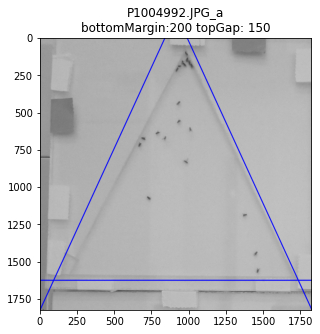

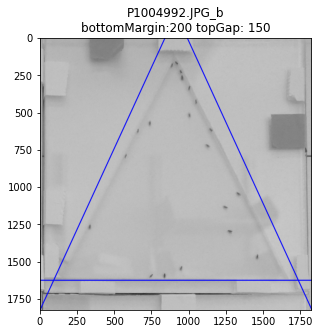

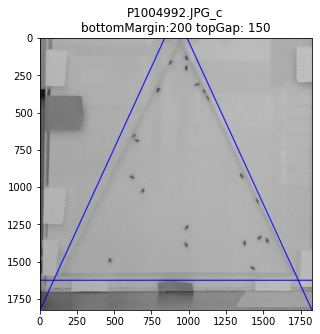

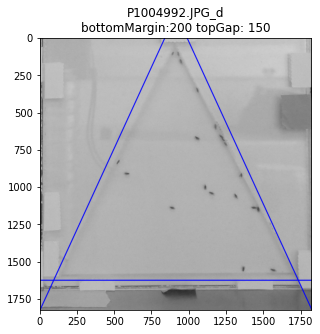

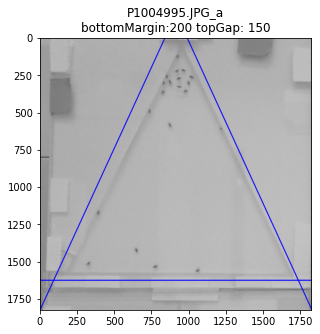

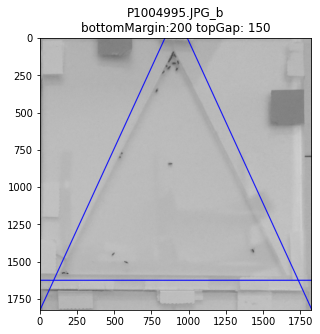

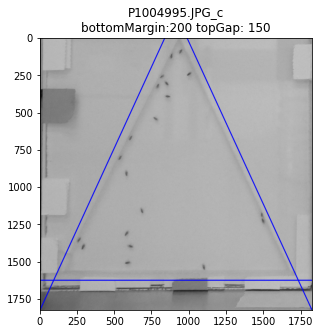

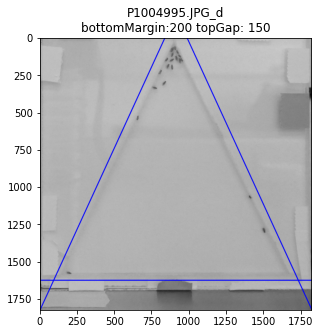

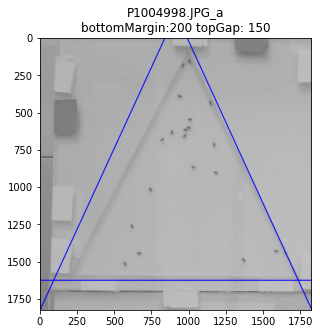

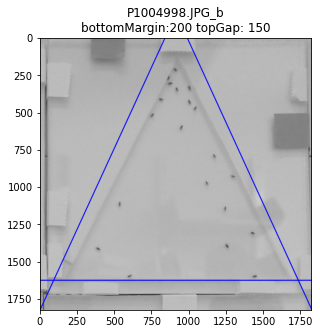

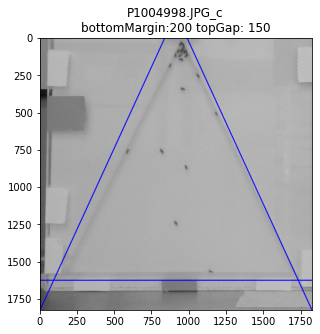

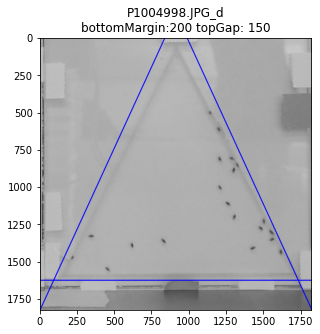

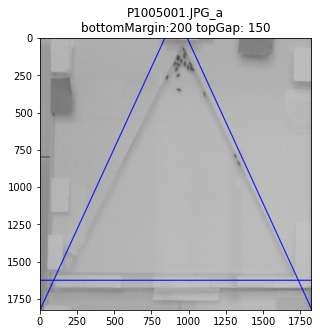

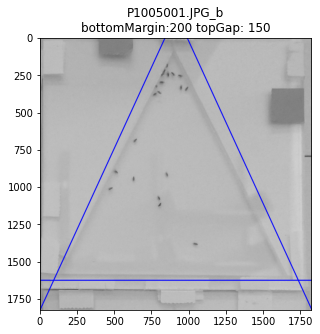

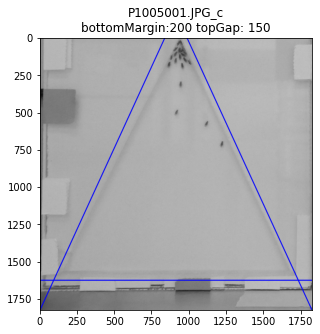

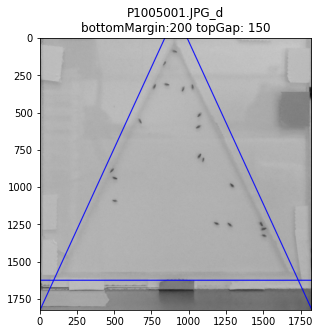

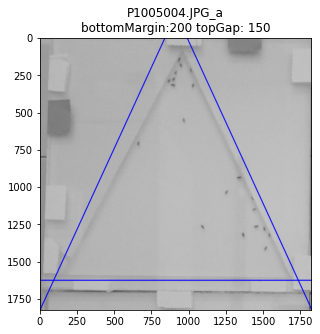

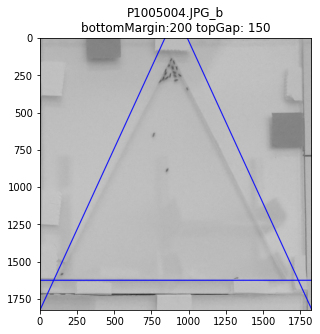

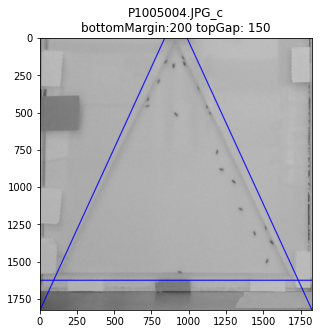

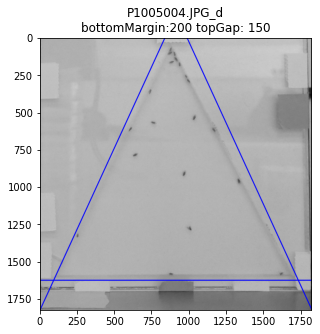

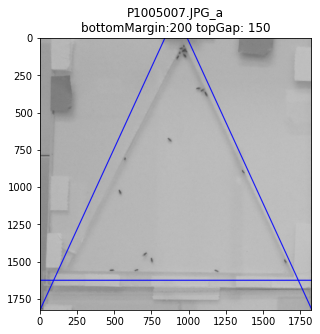

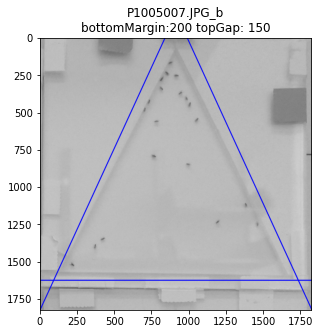

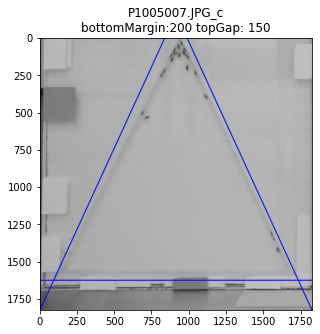

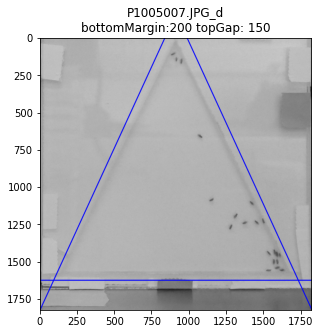

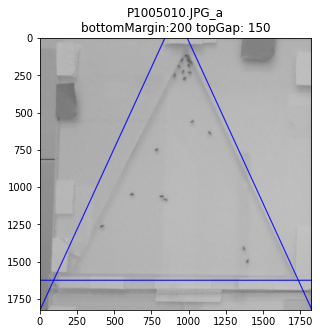

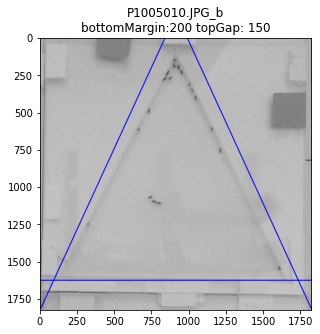

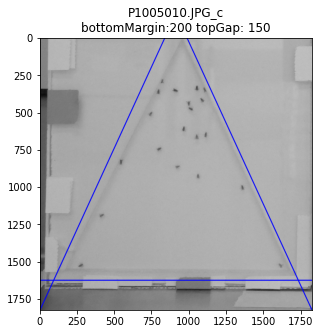

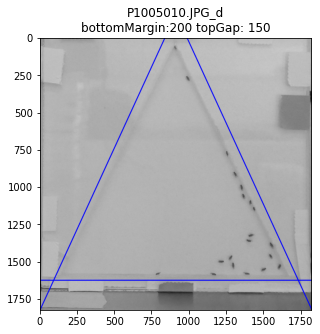

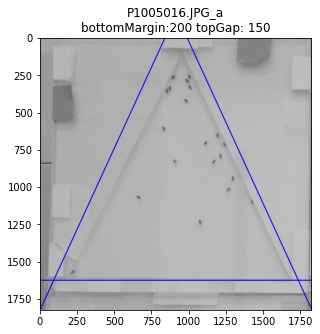

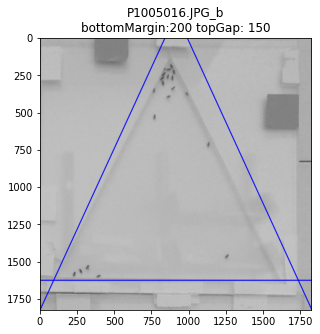

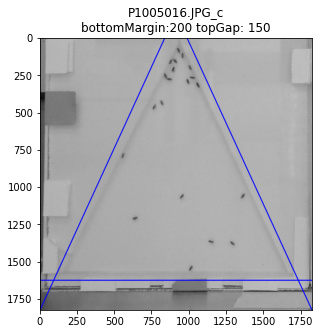

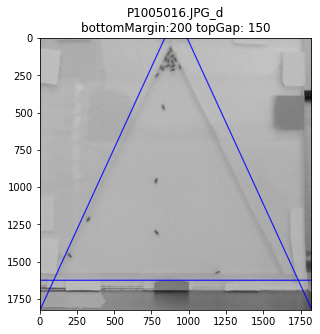

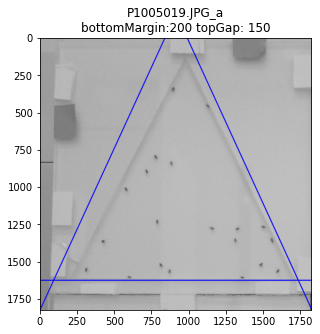

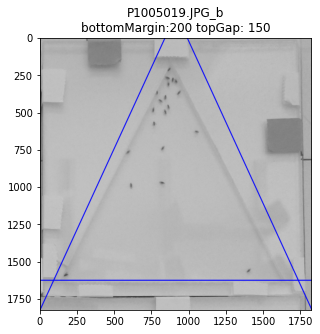

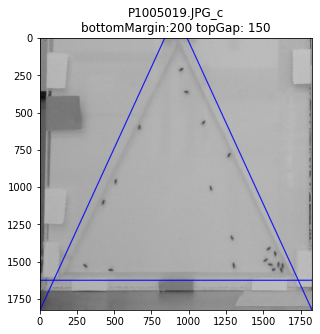

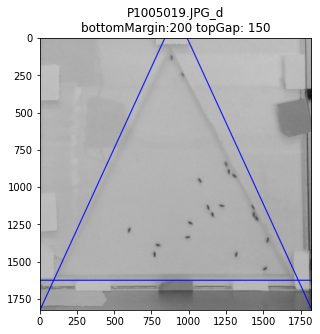

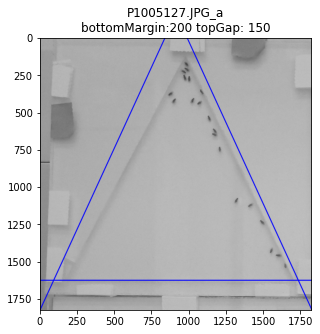

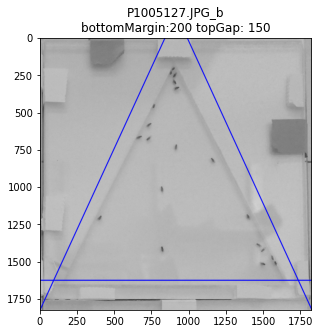

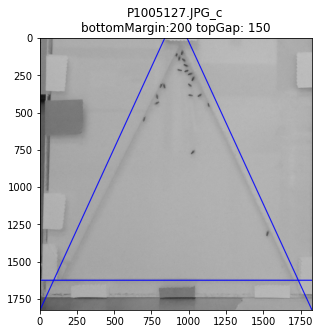

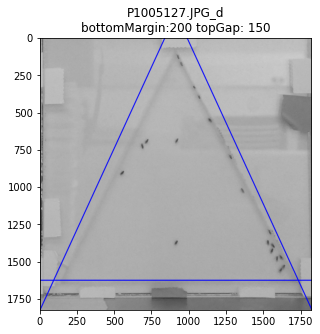

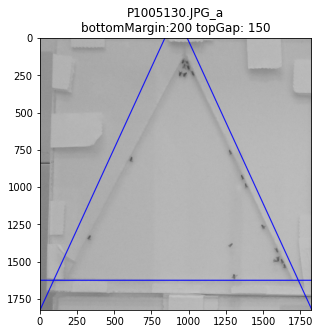

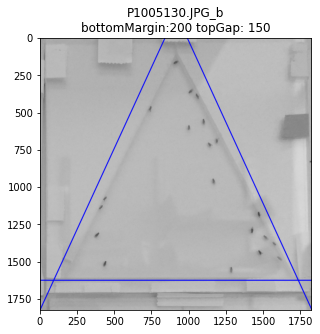

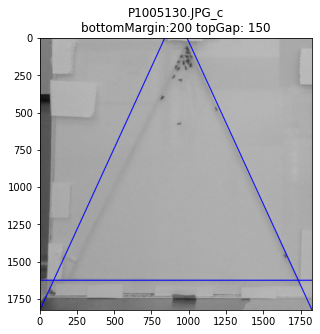

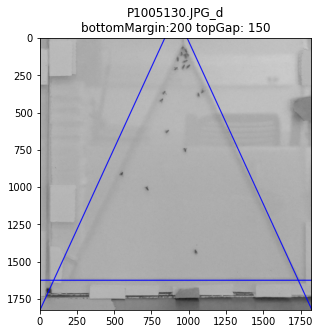

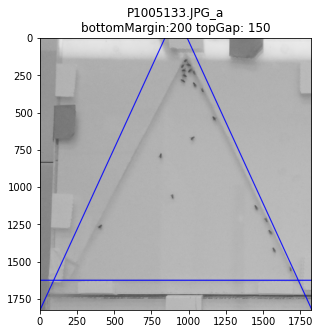

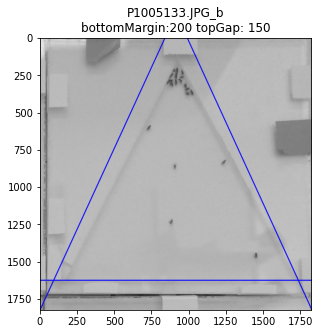

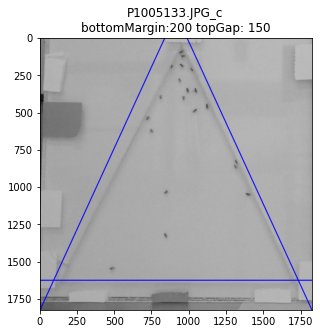

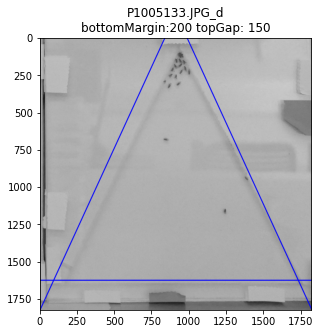

In [9]:
#Cropping the input image if necessary (pxl)
cropLeft4=0
cropRight4=0
cropTop4=0
cropBottom4=0

# Applying the mask:
# bottomMargin : correspond to the marging applied to the bottom of the image
# topgap : correspond to the distance between the two sides-triangle lines (at the top of the picture)   

bottomMargin4=200
topGap4=150

## Visualization
imagPath_="test_4p_2nd//"
viewImageMargins4Panel(imagPath=imagPath_, bottomMargin=bottomMargin4, topGap=topGap4, cropLeft=cropLeft4, cropRight=cropRight4, cropTop=cropTop4, cropBottom=cropBottom4,  marginCol=blue, figSize=figSize, pen_=pen) 


<b>- Checking the names of trained models: both train and first segmentation scripts can help checking available models:</b><br>
Both <i>FlyFinder_train.py</i> and <i> FlyFinder_first_segmentation.py</i> functions can show trained/available models if passe the 'models' parameter.

In [10]:
! python FlyFinder_train.py models


-* FlyFinder_v1.0 *-

Available trained random forest classifiers:

M4Panel_GF40_MF10_Es30_mar100_topG50_RFC
test_2nd




In [11]:
! python FlyFinder_first_segmentation.py models


-* FlyFinder_v1.0 *-

Avalable random forest classifiers:

M4Panel_GF40_MF10_Es30_mar100_topG50_RFC
test_2nd




<b>- Checking the content of the input directory:</b><br>
The directory must contain the images in jpeg format. The file name should end with '.jpg' or '.JPG'

In [8]:
!ls /varidata/research/projects/mnp/tool.dev/FlyFinder_v1.0/test_4p/

log   P1004992.JPG  P1005001.JPG  P1005010.JPG	P1005127.JPG
out   P1004995.JPG  P1005004.JPG  P1005016.JPG	P1005130.JPG
outf  P1004998.JPG  P1005007.JPG  P1005019.JPG	P1005133.JPG


<b>- Running the first segmentation script:</b></br>
The script can be run in <u>parallel</u> using the <b>mpiexec</b> command and by specifying the number <br>
of cores (processors) using the <b>-n</b> parameter. The script can also be run in serial using simply the following command:<br>
<i>python FlyFinder_first_segmentation.py {add command line arguments} </i>
<br><br>
Example of runing the script in parallel:

In [9]:
from FF_utils import *

In [13]:
! mpiexec -n 6  python FlyFinder_first_segmentation.py --modelName test_2nd \
                                                        --plateType 4Panel \
                                                        --minArea 70 \
                                                        --maxArea 350 \
                                                        --nGaussianFilters 40 \
                                                        --nMedianFilters 10 \
                                                        --bottomMargin 200 \
                                                        --topGap 150 \
                                                        --cropLeft 0 \
                                                        --cropRight 0 \
                                                        --cropTop 0 \
                                                        --cropBottom 0 \
                                                        --numFlies 20 \
                                                        --inPath test_4p_2nd/


-* FlyFinder_v1.0 *-




*--- Running FlyFinder Random Forest-based segmantation : core n. 00 ---*

-----------------------------------------------------------------------------------------------

Started time: 2021-08-30 14:20:27.282648



Active path : /Users/Jay.Kim/PycharmProjects/FlyFinder_v1.0/test_4p_2nd/

Settings :
Namespace(modelName='test_2nd', plateType='4Panel', nGaussianFilters=40, nMedianFilters=10, bottomMargin=200, topGap=150, cropLeft=0, cropRight=0, cropTop=0, cropBottom=0, maxArea=350, minArea=70, numFlies=20, inPath='test_4p_2nd/')

Loading the RFC model. Please wait ... 

  Model loaded successfully: /Users/Jay.Kim/PycharmProjects/FlyFinder_v1.0/RFC_model/test_2nd.pkl


  Number of images : 12

['P1004995.JPG', 'P1004992.JPG', 'P1005130.JPG', 'P1005127.JPG', 'P1005133.JPG', 'P1005019.JPG', 'P1005001.JPG', 'P1005016.JPG', 'P1005007.JPG', 'P1005004.JPG', 'P1005010.JPG', 'P1004998.JPG']

P1004995.JPG

 -- Segmenting panel a --
 Generating features, please wait
 Runn

##### <a name="l4"></a>
### <font color='blue'> 2.2. Manual editing the failed images</font>


The output after segmentation contains two directories:<br>
<b>FlyFinder_v1.0/test_4p/out</b> for well segmented images and <b>FlyFinder_v1.0/test_4p/outf</b> for failed images.<br> 
For a quick review of all figures it is recommended to open and check the <b>out.pdf</b> and <b>outf.pdf</b> located in <b>out</b> and <b>outf</b> directories respectively. <br> 

The user must first check for any potential failed images in the out directory and move both the .csv and .jpg files to the <br>
outf directory. All .jpg images in the outf directory must then be manually edited. Editing involves ensuring all flies are <br>
correctly identified by a white 10px by 10px box and background noise (incorrectly labeled white boxes) deleted/blackened. Image<br>
editing can be performed using Fiji or any photo editing software.


In [1]:
!ls /varidata/research/projects/mnp/tool.dev/FlyFinder_v1.0/test_4p/out

out.pdf			       p1005007_panel_c_flies_20.csv
p1004992_panel_a_flies_20.csv  p1005007_panel_c_flies_20.jpg
p1004992_panel_a_flies_20.jpg  p1005007_panel_d_flies_20.csv
p1004992_panel_b_flies_20.csv  p1005007_panel_d_flies_20.jpg
p1004992_panel_b_flies_20.jpg  p1005010_panel_b_flies_20.csv
p1004992_panel_c_flies_20.csv  p1005010_panel_b_flies_20.jpg
p1004992_panel_c_flies_20.jpg  p1005010_panel_c_flies_20.csv
p1004995_panel_a_flies_20.csv  p1005010_panel_c_flies_20.jpg
p1004995_panel_a_flies_20.jpg  p1005010_panel_d_flies_20.csv
p1004995_panel_b_flies_20.csv  p1005010_panel_d_flies_20.jpg
p1004995_panel_b_flies_20.jpg  p1005016_panel_a_flies_20.csv
p1004995_panel_c_flies_20.csv  p1005016_panel_a_flies_20.jpg
p1004995_panel_c_flies_20.jpg  p1005016_panel_c_flies_20.csv
p1004998_panel_a_flies_20.csv  p1005016_panel_c_flies_20.jpg
p1004998_panel_a_flies_20.jpg  p1005016_panel_d_flies_20.csv
p1004998_panel_b_flies_20.csv  p1005016_panel_d_flies_20.jpg
p1004998_panel_b_flies_20.jpg  p100501

In [2]:
!ls /varidata/research/projects/mnp/tool.dev/FlyFinder_v1.0/test_4p/outf

outf.pdf		       p1005016_panel_b_flies_19.jpg
out_ps			       p1005130_panel_a_flies_19.csv
p1004992_panel_d_flies_20.csv  p1005130_panel_a_flies_19.jpg
p1004992_panel_d_flies_20.jpg  p1005130_panel_b_flies_19.csv
p1004995_panel_d_flies_18.csv  p1005130_panel_b_flies_19.jpg
p1004995_panel_d_flies_18.jpg  p1005130_panel_c_flies_19.csv
p1005004_panel_a_flies_19.csv  p1005130_panel_c_flies_19.jpg
p1005004_panel_a_flies_19.jpg  p1005130_panel_d_flies_19.csv
p1005010_panel_a_flies_20.csv  p1005130_panel_d_flies_19.jpg
p1005010_panel_a_flies_20.jpg  p1005133_panel_d_flies_18.csv
p1005016_panel_b_flies_19.csv  p1005133_panel_d_flies_18.jpg


<a name="l5"></a>
### <font color='blue'> 2.3. Performing the second segmentation </font>


Similar to the other scripts, the FlyFinder_second_segmentation.py script can be run in parallel or in serial.<br>
Below is an example of how to run in parallel.

In [3]:
from FF_utils import *

In [14]:
! mpiexec -n 4  python FlyFinder_second_segmentation.py  --inPath test_4p_2nd//outf


-* FlyFinder_v1.0 *-


Performing segmantation for image where flies are marked with 10x10 pxl white points (squares)
----------------------------------------------------------------------------------------
Started time: 2021-08-30 14:25:35.567762



Active path : test_4p_2nd//outf/


Number of images 8



p1005016_panel_b_flies_19.jpg

p1004995_panel_d_flies_18.jpg
Time elabsed: 0.03 min / 1.53 seconds 


done
Duration: 0.03 min / 1.62 seconds



*---  FlyFinder post-processing segmentation completed successfully! ---*


End time: 2021-08-30 14:25:37.183561




Viewing the output after post-procesing. Directory FlyFinderV2.0/test_4p/outf/out_ps

In [6]:
! ls /varidata/research/projects/mnp/tool.dev/FlyFinder_v1.0/test_4p/outf/out_ps

out_ps.pdf
p1004992_panel_d_flies_20_flies_21_ps.csv
p1004992_panel_d_flies_20_flies_21_ps.jpg
p1004995_panel_d_flies_18_flies_20_ps.csv
p1004995_panel_d_flies_18_flies_20_ps.jpg
p1005004_panel_a_flies_19_flies_20_ps.csv
p1005004_panel_a_flies_19_flies_20_ps.jpg
p1005010_panel_a_flies_20_flies_20_ps.csv
p1005010_panel_a_flies_20_flies_20_ps.jpg
p1005016_panel_b_flies_19_flies_20_ps.csv
p1005016_panel_b_flies_19_flies_20_ps.jpg
p1005130_panel_a_flies_19_flies_20_ps.csv
p1005130_panel_a_flies_19_flies_20_ps.jpg
p1005130_panel_b_flies_19_flies_20_ps.csv
p1005130_panel_b_flies_19_flies_20_ps.jpg
p1005130_panel_c_flies_19_flies_20_ps.csv
p1005130_panel_c_flies_19_flies_20_ps.jpg
p1005130_panel_d_flies_19_flies_20_ps.csv
p1005130_panel_d_flies_19_flies_20_ps.jpg
p1005133_panel_d_flies_18_flies_20_ps.csv
p1005133_panel_d_flies_18_flies_20_ps.jpg


<a name="l6"></a>
### <font color='blue'> 2.4. Creating the table of fly coordinates</font>

A python script is used to compile one main table that combines all tables of  xy-coordinates of fly location from each image

In [15]:
! python FlyFinder_maketable.py --inPath  test_4p_2nd//


* RFC segmantation : Number of tables = 40

p1004992_panel_a_flies_20.csv
p1004992_panel_b_flies_20.csv
p1004992_panel_c_flies_20.csv
p1004992_panel_d_flies_20.csv
p1004995_panel_a_flies_20.csv
p1004995_panel_b_flies_20.csv
p1004995_panel_c_flies_20.csv
p1004998_panel_a_flies_20.csv
p1004998_panel_b_flies_20.csv
p1004998_panel_c_flies_20.csv
p1004998_panel_d_flies_20.csv
p1005001_panel_a_flies_20.csv
p1005001_panel_b_flies_20.csv
p1005001_panel_c_flies_20.csv
p1005001_panel_d_flies_20.csv
p1005004_panel_b_flies_20.csv
p1005004_panel_c_flies_20.csv
p1005004_panel_d_flies_20.csv
p1005007_panel_a_flies_20.csv
p1005007_panel_b_flies_20.csv
p1005007_panel_c_flies_20.csv
p1005007_panel_d_flies_20.csv
p1005010_panel_a_flies_20.csv
p1005010_panel_b_flies_20.csv
p1005010_panel_c_flies_20.csv
p1005010_panel_d_flies_20.csv
p1005016_panel_a_flies_20.csv
p1005016_panel_c_flies_20.csv
p1005016_panel_d_flies_20.csv
p1005019_panel_a_flies_20.csv
p1005019_panel_b_flies_20.csv
p1005019_panel_c_flies_20

<a name="l7"></a>
### <font color='blue'> 2.5. Calculating the nearest neighbors distances</font>

An R command computes the first, second, third and average nearest neighbor distances, compiling them into final tables and figures.<br>
It is required to specify the image width <b>imgWidht</b> and images hieght <b>imgHeight</b><br>
In this case it s 3648 pxl / 2 = 1824 pxl i.e the lenght of a side of each of the 4 panels.




In [16]:
! ./Neighbor_distances.R --inPath  test_4p_2nd// --imgWidth 1824 --imgHeight 1824



 * ----  Computing nearest neigbor distance  ---- *

 Path of x-y coordiate table :  test_4p_2nd//
 Images width  (pxl) :  1824
 Images hieght (pxl) :  1824
p1004992_panel_a_flies_20.jpg 
p1004992_panel_b_flies_20.jpg 
p1004992_panel_c_flies_20.jpg 
p1004992_panel_d_flies_20.jpg 
p1004995_panel_a_flies_20.jpg 
p1004995_panel_b_flies_20.jpg 
p1004995_panel_c_flies_20.jpg 
p1004998_panel_a_flies_20.jpg 
p1004998_panel_b_flies_20.jpg 
p1004998_panel_c_flies_20.jpg 
p1004998_panel_d_flies_20.jpg 
p1005001_panel_a_flies_20.jpg 
p1005001_panel_b_flies_20.jpg 
p1005001_panel_c_flies_20.jpg 
p1005001_panel_d_flies_20.jpg 
p1005004_panel_b_flies_20.jpg 
p1005004_panel_c_flies_20.jpg 
p1005004_panel_d_flies_20.jpg 
p1005007_panel_a_flies_20.jpg 
p1005007_panel_b_flies_20.jpg 
p1005007_panel_c_flies_20.jpg 
p1005007_panel_d_flies_20.jpg 
p1005010_panel_a_flies_20.jpg 
p1005010_panel_b_flies_20.jpg 
p1005010_panel_c_flies_20.jpg 
p1005010_panel_d_flies_20.jpg 
p1005016_panel_a_flies_20.jpg 
p100

### <font color='blue'>    *   Here ends of the pipeline  *